# Model Comparison

Our CatBoost baseline achieved an **OOF ROC-AUC of 0.946094**.

We will compare LightGBM and XGBoost on the same folds, then test whether combining their predictions with CatBoost improves ROC-AUC.

## 1. Load Data

Use the original features and saved CatBoost OOF predictions.

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

SEED = 42
N_SPLITS = 5

root = Path("../playground-series-s6e11")
train_df = pd.read_csv(root / "train.csv")
catboost_oof = pd.read_csv("baseline_artifacts/baseline_oof.csv")

features = [c for c in train_df.columns if c not in ["id", "is_fraud"]]
y = train_df["is_fraud"].astype(int)

print("Train:", train_df.shape)
print("CatBoost OOF:", catboost_oof.shape)

Train: (699960, 26)
CatBoost OOF: (699960, 4)


## 2. Prepare Features

LightGBM can use categorical columns directly. For XGBoost, we will use one-hot encoding to keep the setup simple and compatible.

In [9]:
X = train_df[features].copy()

cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
bool_cols = X.select_dtypes(include=["bool", "boolean"]).columns.tolist()

for col in cat_cols:
    X[col] = X[col].astype("category")

for col in bool_cols:
    X[col] = X[col].astype(int)

X_xgb = pd.get_dummies(X, columns=cat_cols, dtype=int)

print("LightGBM features:", X.shape[1])
print("XGBoost features:", X_xgb.shape[1])

LightGBM features: 24
XGBoost features: 54


## 3. LightGBM Cross-Validation

Train LightGBM with the same five folds as CatBoost. Save one OOF prediction per transaction.

In [10]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

params = {
    "objective": "binary",
    "metric": "auc",
    "n_estimators": 3000,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "random_state": SEED,
    "verbosity": -1,
    "n_jobs": -1,
}

lgb_oof = np.zeros(len(X))
fold_scores = []
models = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
    model = lgb.LGBMClassifier(**params)
    model.fit(
        X.iloc[train_idx], y.iloc[train_idx],
        eval_set=[(X.iloc[valid_idx], y.iloc[valid_idx])],
        eval_metric="auc",
        categorical_feature=cat_cols,
        callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False)],
    )

    pred = model.predict_proba(X.iloc[valid_idx])[:, 1]
    lgb_oof[valid_idx] = pred
    auc = roc_auc_score(y.iloc[valid_idx], pred)
    fold_scores.append(auc)
    models.append(model)
    print(f"Fold {fold}: AUC={auc:.6f}, best iteration={model.best_iteration_}")

lgb_auc = roc_auc_score(y, lgb_oof)
print(f"\nLightGBM OOF ROC-AUC: {lgb_auc:.6f}")

/Users/ulad/kaggle/fraud_detection/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: AUC=0.943456, best iteration=396


/Users/ulad/kaggle/fraud_detection/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: AUC=0.946968, best iteration=376


/Users/ulad/kaggle/fraud_detection/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3: AUC=0.950113, best iteration=187


/Users/ulad/kaggle/fraud_detection/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: AUC=0.945788, best iteration=283


/Users/ulad/kaggle/fraud_detection/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5: AUC=0.940230, best iteration=348

LightGBM OOF ROC-AUC: 0.945159


## 4. XGBoost Cross-Validation

Train XGBoost on exactly the same five folds and save its OOF predictions.

In [11]:
xgb_params = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "n_estimators": 3000,
    "learning_rate": 0.05,
    "max_depth": 6,
    "tree_method": "hist",
    "random_state": SEED,
    "n_jobs": -1,
    "early_stopping_rounds": 100,
}

xgb_oof = np.zeros(len(X_xgb))
xgb_fold_scores = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_xgb, y), start=1):
    model = xgb.XGBClassifier(**xgb_params)
    model.fit(
        X_xgb.iloc[train_idx], y.iloc[train_idx],
        eval_set=[(X_xgb.iloc[valid_idx], y.iloc[valid_idx])],
        verbose=False,
    )

    pred = model.predict_proba(X_xgb.iloc[valid_idx])[:, 1]
    xgb_oof[valid_idx] = pred
    auc = roc_auc_score(y.iloc[valid_idx], pred)
    xgb_fold_scores.append(auc)
    print(f"Fold {fold}: AUC={auc:.6f}, best iteration={model.best_iteration}")

xgb_auc = roc_auc_score(y, xgb_oof)
print(f"\nXGBoost OOF ROC-AUC: {xgb_auc:.6f}")


Fold 1: AUC=0.943552, best iteration=333
Fold 2: AUC=0.947252, best iteration=314
Fold 3: AUC=0.949994, best iteration=236
Fold 4: AUC=0.945465, best iteration=288
Fold 5: AUC=0.940462, best iteration=543

XGBoost OOF ROC-AUC: 0.945122


## 5. Compare OOF Results

Compare all three models using predictions for the same transactions and folds.

In [12]:
# Align saved CatBoost predictions by ID
baseline = train_df[["id", "is_fraud"]].merge(
    catboost_oof[["id", "fold", "oof_pred"]], on="id", how="left"
)

assert len(baseline) == len(train_df)
assert baseline["oof_pred"].notna().all()

fold_ids = np.zeros(len(X), dtype=int)
for fold, (_, valid_idx) in enumerate(cv.split(X, y), start=1):
    fold_ids[valid_idx] = fold
assert np.array_equal(fold_ids, baseline["fold"].to_numpy())

cb_pred = baseline["oof_pred"].to_numpy()
cb_auc = roc_auc_score(y, cb_pred)

comparison = pd.DataFrame({
    "model": ["CatBoost", "LightGBM", "XGBoost"],
    "oof_auc": [cb_auc, lgb_auc, xgb_auc],
})
comparison["delta_vs_catboost"] = comparison["oof_auc"] - cb_auc

display(comparison)

,model,oof_auc,delta_vs_catboost
0,CatBoost,0.946094,0.000000
1,LightGBM,0.945159,-0.000935
2,XGBoost,0.945122,-0.000972


## 6. Do the Models Disagree?

Compare prediction correlations. Models that make different predictions may be useful for blending.

,catboost,lightgbm,xgboost
catboost,1.0000,0.9705,0.9765
lightgbm,0.9705,1.0000,0.9752
xgboost,0.9765,0.9752,1.0000


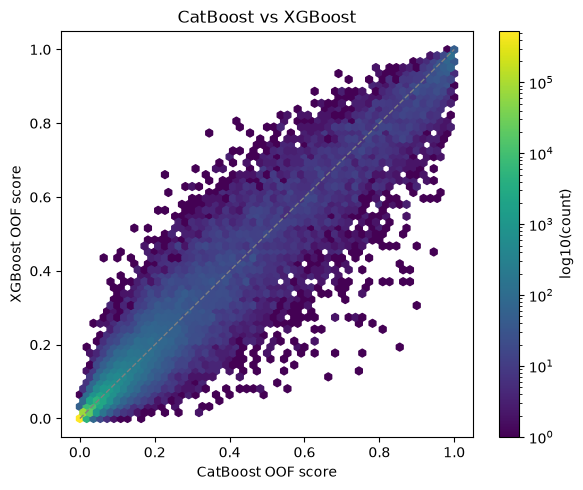

In [13]:
predictions_df = pd.DataFrame({
    "catboost": cb_pred,
    "lightgbm": lgb_oof,
    "xgboost": xgb_oof,
})

display(predictions_df.corr().round(4))

plt.figure(figsize=(6, 5))
plt.hexbin(cb_pred, xgb_oof, gridsize=55, bins="log", mincnt=1)
plt.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
plt.xlabel("CatBoost OOF score")
plt.ylabel("XGBoost OOF score")
plt.title("CatBoost vs XGBoost")
plt.colorbar(label="log10(count)")
plt.tight_layout()
plt.show()

## 7. Simple Blending

Test a few fixed combinations without optimizing weights on the OOF labels.

In [14]:
blends = {
    "CatBoost + LightGBM": (cb_pred + lgb_oof) / 2,
    "CatBoost + XGBoost": (cb_pred + xgb_oof) / 2,
    "LightGBM + XGBoost": (lgb_oof + xgb_oof) / 2,
    "All three": (cb_pred + lgb_oof + xgb_oof) / 3,
}

blend_results = pd.DataFrame([
    {"blend": name, "oof_auc": roc_auc_score(y, pred)}
    for name, pred in blends.items()
])
blend_results["delta_vs_catboost"] = blend_results["oof_auc"] - cb_auc

display(blend_results.sort_values("oof_auc", ascending=False))

,blend,oof_auc,delta_vs_catboost
3,All three,0.946414,0.000320
0,CatBoost + LightGBM,0.946374,0.000279
1,CatBoost + XGBoost,0.946361,0.000266
2,LightGBM + XGBoost,0.945743,-0.000352


## 8. Save Results

Save LightGBM and XGBoost OOF predictions and the comparison tables.

In [15]:
output_dir = Path("model_comparison_artifacts")
output_dir.mkdir(exist_ok=True)

pd.DataFrame({
    "id": train_df["id"],
    "is_fraud": y,
    "fold": fold_ids,
    "lgb_oof_pred": lgb_oof,
    "xgb_oof_pred": xgb_oof,
}).to_csv(output_dir / "other_models_oof.csv", index=False)

comparison.to_csv(output_dir / "model_comparison.csv", index=False)
blend_results.to_csv(output_dir / "blend_results.csv", index=False)

print("Saved to:", output_dir)

Saved to: model_comparison_artifacts


## Findings

**CatBoost** remains our best individual model, with an OOF ROC-AUC of **0.946094**.

**LightGBM** and **XGBoost** performed slightly worse, but combining all three models improved ROC-AUC to **0.946414**.

The predictions are highly correlated, but the models still seem to capture slightly different patterns.

**Next step:** Check whether the blending improvement is consistent across folds before exploring more advanced approaches.

In [17]:
blend_pred = blends["All three"]

results = []

for fold in range(1, N_SPLITS + 1):
    mask = fold_ids == fold

    cb = roc_auc_score(y[mask], cb_pred[mask])
    blend = roc_auc_score(y[mask], blend_pred[mask])

    results.append({
        "fold": fold,
        "catboost": cb,
        "blend": blend,
        "delta": blend - cb
    })

display(pd.DataFrame(results))

,fold,catboost,blend,delta
0,1,0.944562,0.944921,0.000359
1,2,0.947463,0.947963,0.000500
2,3,0.950552,0.951104,0.000552
3,4,0.946352,0.946678,0.000326
4,5,0.941891,0.942036,0.000146


### Blending Results

Combining `CatBoost`, `LightGBM`, and `XGBoost` improved OOF `ROC-AUC` from **0.946094 to 0.946414**.

The blend performed better than CatBoost on all five validation folds, suggesting that the models capture slightly different patterns.

Although the improvement is small, blending looks more promising than the simple feature engineering experiments we tried earlier.

In [19]:
from scipy.stats import rankdata

rank_blend = (
    rankdata(cb_pred) +
    rankdata(lgb_oof) +
    rankdata(xgb_oof)
) / 3

rank_auc = roc_auc_score(y, rank_blend)

print(f"Rank blend AUC: {rank_auc:.6f}")
print(f"Delta vs score blend: {rank_auc - 0.946414:+.6f}")

Rank blend AUC: 0.946447
Delta vs score blend: +0.000033


### Rank Averaging

Rank averaging slightly improved OOF `ROC-AUC` from **0.946414 to 0.946447** compared to score blending.

The improvement is very small, but rank averaging appears to be another promising ensemble approach.